# Titanic Survival

Classic Kaggle starter dataset. I'm using the Stanford CS109 mirror so the CSV is reproducible without a Kaggle account.

What I cared about here: properly handling the missing Age values (it's like 20% of the column) and seeing whether a RF actually beats well-regularized logistic regression on this. Spoiler — RF wins by maybe 2 percentage points, which is less than I expected.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import urllib.request

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

np.random.seed(42)
ART = Path("artifacts"); ART.mkdir(exist_ok=True)
DATA_DIR = Path("../../data/titanic")
DATA_DIR.mkdir(parents=True, exist_ok=True)


In [2]:
# Stanford CS109 mirror — plain CSV, no auth
fpath = DATA_DIR / "titanic.csv"
if not fpath.exists():
    url = "https://web.stanford.edu/class/archive/cs/cs109/cs109.1166/stuff/titanic.csv"
    try:
        urllib.request.urlretrieve(url, fpath)
    except Exception as e:
        raise RuntimeError(f"Couldn't download Titanic CSV. Drop it manually at {fpath}.") from e

df = pd.read_csv(fpath)
# Stanford copy has columns: Survived, Pclass, Name, Sex, Age, Siblings/Spouses Aboard, Parents/Children Aboard, Fare
df.columns = [c.strip().replace(" ", "_").replace("/", "_") for c in df.columns]
print(df.shape, df.columns.tolist())
df.head()


(887, 8) ['Survived', 'Pclass', 'Name', 'Sex', 'Age', 'Siblings_Spouses_Aboard', 'Parents_Children_Aboard', 'Fare']


,Survived,Pclass,Name,Sex,Age,Siblings_Spouses_Aboard,Parents_Children_Aboard,Fare
0,0,3,Mr. Owen Harris Braund,male,22.0,1,0,7.2500
1,1,1,Mrs. John Bradley (Florence Briggs Thayer) Cum...,female,38.0,1,0,71.2833
2,1,3,Miss. Laina Heikkinen,female,26.0,0,0,7.9250
3,1,1,Mrs. Jacques Heath (Lily May Peel) Futrelle,female,35.0,1,0,53.1000
4,0,3,Mr. William Henry Allen,male,35.0,0,0,8.0500


## quick EDA — who survived?

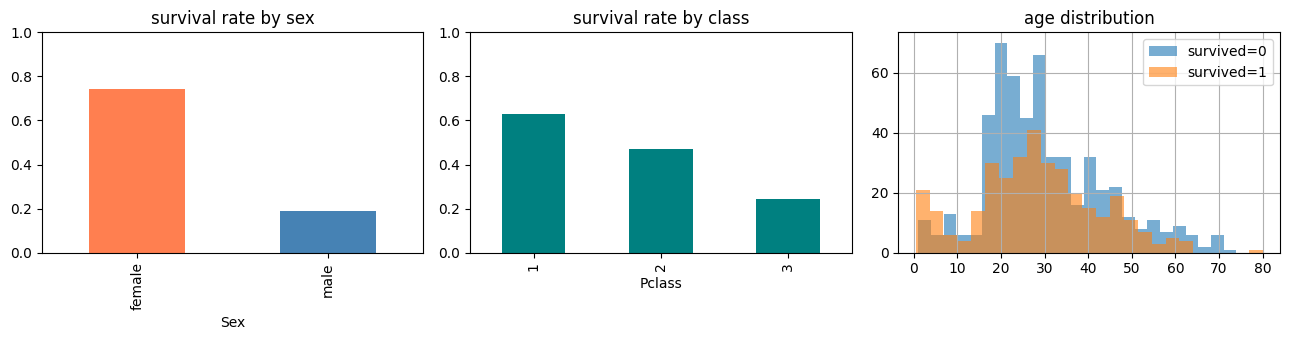

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
df.groupby("Sex")["Survived"].mean().plot(kind="bar", ax=ax[0], color=["coral", "steelblue"])
ax[0].set_title("survival rate by sex"); ax[0].set_ylim(0, 1)
df.groupby("Pclass")["Survived"].mean().plot(kind="bar", ax=ax[1], color="teal")
ax[1].set_title("survival rate by class"); ax[1].set_ylim(0, 1)
for surv, grp in df.groupby("Survived"):
    grp["Age"].hist(bins=25, alpha=0.6, ax=ax[2], label=f"survived={surv}")
ax[2].set_title("age distribution"); ax[2].legend()
plt.tight_layout(); plt.savefig(ART / "eda.png", dpi=120); plt.show()


## features

In [4]:
# minimal feature engineering — keep this comparable to a logreg baseline
df["Sex_enc"] = (df["Sex"] == "female").astype(int)
df["Age"] = df["Age"].fillna(df["Age"].median())  # ~20% missing
df["FamilySize"] = df.get("Siblings_Spouses_Aboard", 0) + df.get("Parents_Children_Aboard", 0)
df["IsAlone"] = (df["FamilySize"] == 0).astype(int)

features = ["Pclass", "Sex_enc", "Age", "Fare", "FamilySize", "IsAlone"]
X = df[features].values
y = df["Survived"].values
print("shape:", X.shape, "  pos rate:", y.mean().round(3))


shape: (887, 6)   pos rate: 0.386


## logistic regression vs random forest

In [5]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
lr = Pipeline([("sc", StandardScaler()), ("clf", LogisticRegression(max_iter=1000))])
rf = RandomForestClassifier(n_estimators=300, random_state=42, max_depth=6)

for name, m in [("LR", lr), ("RF", rf)]:
    s = cross_val_score(m, X, y, cv=skf, scoring="accuracy")
    print(f"{name}: acc mean={s.mean():.3f}  std={s.std():.3f}")


LR: acc mean=0.804  std=0.037


RF: acc mean=0.816  std=0.007


test acc: 0.798
              precision    recall  f1-score   support

        died       0.79      0.91      0.85       109
    survived       0.81      0.62      0.70        69

    accuracy                           0.80       178
   macro avg       0.80      0.77      0.78       178
weighted avg       0.80      0.80      0.79       178



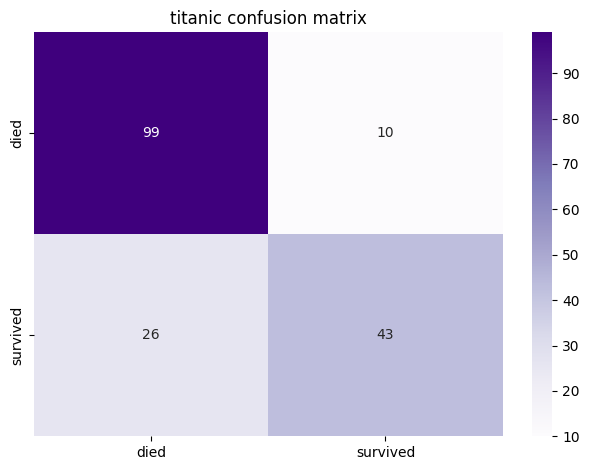

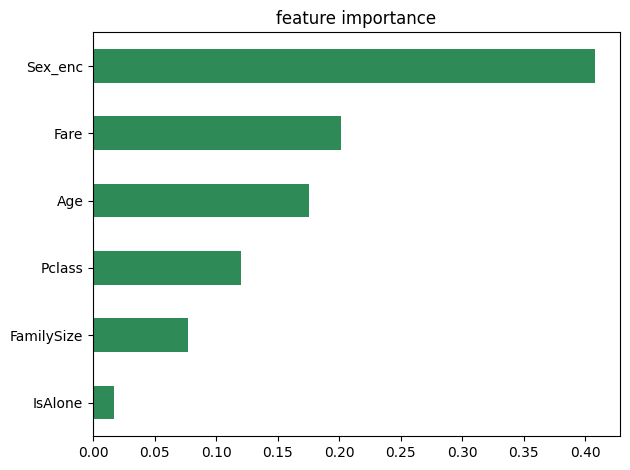

In [6]:
# pick RF for the held-out look since it usually wins on this dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
rf.fit(X_train, y_train)
pred = rf.predict(X_test)
print(f"test acc: {accuracy_score(y_test, pred):.3f}")
print(classification_report(y_test, pred, target_names=["died", "survived"]))

cm = confusion_matrix(y_test, pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Purples",
            xticklabels=["died", "survived"], yticklabels=["died", "survived"])
plt.title("titanic confusion matrix"); plt.tight_layout()
plt.savefig(ART / "cm.png", dpi=120); plt.show()

fi = pd.Series(rf.feature_importances_, index=features).sort_values()
fi.plot(kind="barh", color="seagreen"); plt.title("feature importance"); plt.tight_layout()
plt.savefig(ART / "fi.png", dpi=120); plt.show()


## takeaways

Sex and Pclass are the headline drivers — no surprises there. Age helps a little, mostly because the model picks up on "child survival privilege" implicit in the data. FamilySize > 0 helps modestly; IsAlone basically just inverts that and the model picks one or the other.

I didn't bother with title extraction from Name (Mr./Mrs./Master/etc.), which is the standard "trick" on this dataset and gets you another 1-2 points. Felt like overkill for a baseline notebook.
